# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import os

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torchvision import datasets
from torchvision import transforms as tfs

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from _bootstrap import setup
from src.vasijas.reporting import ProcessingReport

In [2]:
# Configuración general
PATHS = setup()
report = ProcessingReport()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 16
EPOCHS = 75
LR = 3e-4
UNFREEZE_EPOCH = 10
BACKBONE_LR_FACTOR = 0.1
BACKBONE_LR = LR * BACKBONE_LR_FACTOR

NUM_WORKERS = min(8, os.cpu_count() or 1)
PIN_MEMORY = DEVICE.type == "cuda"
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
USE_CHANNELS_LAST = DEVICE.type == "cuda"
ENABLE_MODEL_COMPILE = False

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision("high")

IMG_SIZE = 224

FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.8, 1.0)
ROTATION_DEGREES = (-15, 15)
PIXEL_FILL = (255, 255, 255)

SEED = 42

DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_NAME = "resnet18"

print("Device:", DEVICE)
print(
    f"Config -> batch_size: {BATCH_SIZE}, workers: {NUM_WORKERS}, "
    f"pin_memory: {PIN_MEMORY}, amp: {USE_AMP}"
)

Device: cuda
Config -> batch_size: 16, workers: 8, pin_memory: True, amp: True


In [3]:
# Transformaciones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = tfs.Compose(
    [
        tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
        tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
        tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
        tfs.RandomAffine(degrees=0, scale=SCALING_FACTOR_INTERVAL, fill=PIXEL_FILL),
        tfs.ToTensor(),
        tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

val_transforms = tfs.Compose(
    [
        tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
        tfs.ToTensor(),
        tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

test_transforms = val_transforms


class TransformSubset(Dataset):
    """Subset por indices que aplica transform al vuelo."""

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.dataset[
            self.indices[i]
        ]  # x es PIL si dataset base no tiene transform
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# a) Dataset base SIN transformaciones
full_dataset = datasets.ImageFolder(DATA_DIR)

indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# train vs temp
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices, labels, test_size=0.30, stratify=labels, random_state=SEED
)

# val vs test
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_labels, random_state=SEED
)

train_dataset = TransformSubset(full_dataset, train_idx, transform=train_transforms)
val_dataset = TransformSubset(full_dataset, val_idx, transform=val_transforms)
test_dataset = TransformSubset(full_dataset, test_idx, transform=test_transforms)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
    drop_last=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
)

class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

# Pesos inversos a la frecuencia para reducir el sesgo hacia clases mayoritarias.
train_class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights = train_class_counts.sum() / (
    NUM_CLASSES * np.maximum(train_class_counts, 1)
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

print("Clases:", class_names)
print("Conteo train por clase:", train_class_counts.tolist())
print("Pesos de clase:", class_weights.round(3).tolist())
print(
    f"Split -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}"
)

Clases: ['clase01', 'clase02', 'clase03', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Conteo train por clase: [18, 32, 50, 39, 36, 34, 196, 14, 248, 82]
Pesos de clase: [4.161, 2.341, 1.498, 1.921, 2.081, 2.203, 0.382, 5.35, 0.302, 0.913]
Split -> train: 749, val: 161, test: 161


In [4]:
from torchvision.models import ResNet18_Weights


# 3. Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


# Modelo (reemplaza rama resnet18 en get_model)
def get_model(model_name, num_classes):
    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT  # equivalente a IMAGENET1K_V1
        model = models.resnet18(weights=weights, progress=True)

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights="IMAGENET1K_V1")
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Modelo no soportado")

    return model.to(DEVICE)


model = get_model(MODEL_NAME, NUM_CLASSES)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

if ENABLE_MODEL_COMPILE and hasattr(torch, "compile") and DEVICE.type == "cuda":
    model = torch.compile(model)

In [5]:
# 5. Funciones de 03.entrenamiento y validación
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
scaler = torch.amp.GradScaler(device=DEVICE.type, enabled=USE_AMP)

# Optimizador (ajusta para entrenar solo lo descongelado)
optimizer = optim.Adam(
    [
        {
            "params": [p for p in model.parameters() if p.requires_grad],
            "lr": LR,
            "name": "head",
        }
    ],
    lr=LR,
)


def maybe_unfreeze_layer4(model, optimizer, epoch):
    if (
        MODEL_NAME != "resnet18"
        or epoch != UNFREEZE_EPOCH
        or not hasattr(model, "layer4")
    ):
        return False

    if any(group.get("name") == "layer4" for group in optimizer.param_groups):
        return False

    layer4_params = []
    for param in model.layer4.parameters():
        param.requires_grad = True
        layer4_params.append(param)

    optimizer.add_param_group(
        {"params": layer4_params, "lr": BACKBONE_LR, "name": "layer4"}
    )
    return True


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc


def validate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=PIN_MEMORY)
            labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
            if USE_CHANNELS_LAST:
                images = images.to(memory_format=torch.channels_last)

            with torch.autocast(
                device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc, all_preds, all_labels

In [6]:
# 6. Loop de 03.entrenamiento
from datetime import datetime

train_losses, val_losses = [], []
train_accs, val_accs = [], []
unfrozen = False

for epoch in range(EPOCHS):
    if not unfrozen:
        unfrozen = maybe_unfreeze_layer4(model, optimizer, epoch)
        if unfrozen:
            print(
                f"Epoch {epoch + 1}: se descongela layer4 con lr={BACKBONE_LR:.2e} "
                f"(head lr={LR:.2e})"
            )

    momento_inicio = datetime.now()

    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, preds, labels = validate(model, val_loader)

    momento_fin = datetime.now()
    tiempo_epoch = momento_fin - momento_inicio

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Tiempo de epoch: {tiempo_epoch}")

Epoch 1/75
Train Loss: 2.4155 | Train Acc: 0.1148
Val Loss: 2.2448 | Val Acc: 0.0807
Tiempo de epoch: 0:00:06.718176
Epoch 2/75
Train Loss: 2.1129 | Train Acc: 0.3792
Val Loss: 2.0807 | Val Acc: 0.3354
Tiempo de epoch: 0:00:05.039728
Epoch 3/75
Train Loss: 1.9743 | Train Acc: 0.4579
Val Loss: 1.9389 | Val Acc: 0.4348
Tiempo de epoch: 0:00:04.888125
Epoch 4/75
Train Loss: 1.8484 | Train Acc: 0.5354
Val Loss: 1.8246 | Val Acc: 0.4720
Tiempo de epoch: 0:00:04.941048
Epoch 5/75
Train Loss: 1.7048 | Train Acc: 0.6275
Val Loss: 1.8052 | Val Acc: 0.4534
Tiempo de epoch: 0:00:04.891766
Epoch 6/75
Train Loss: 1.6272 | Train Acc: 0.6248
Val Loss: 1.6987 | Val Acc: 0.5031
Tiempo de epoch: 0:00:05.067192
Epoch 7/75
Train Loss: 1.5538 | Train Acc: 0.6676
Val Loss: 1.6628 | Val Acc: 0.4907
Tiempo de epoch: 0:00:04.922830
Epoch 8/75
Train Loss: 1.4768 | Train Acc: 0.6662
Val Loss: 1.6099 | Val Acc: 0.4845
Tiempo de epoch: 0:00:04.934501
Epoch 9/75
Train Loss: 1.4507 | Train Acc: 0.6502
Val Loss: 1.63

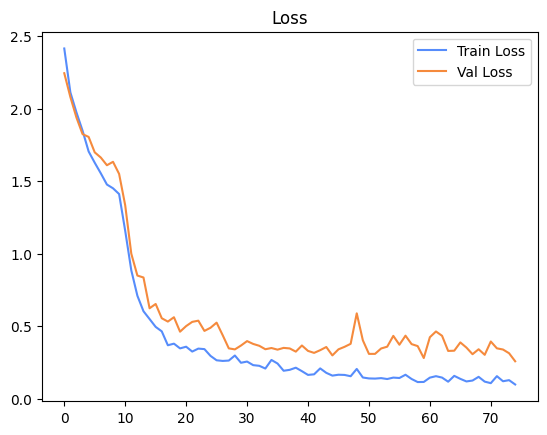

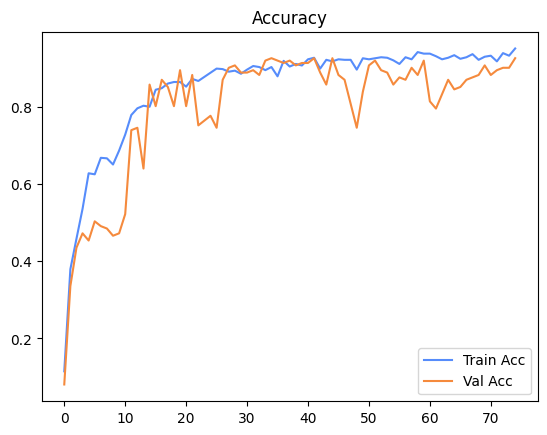

In [7]:
# 7. Curvas de 03.entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.8820
              precision    recall  f1-score   support

     clase01       0.80      1.00      0.89         4
     clase02       0.45      0.71      0.56         7
     clase03       0.77      0.91      0.83        11
     clase05       0.78      0.88      0.82         8
     clase06       1.00      0.50      0.67         8
     clase07       1.00      0.86      0.92         7
     clase08       0.90      0.86      0.88        42
     clase09       0.67      0.67      0.67         3
     clase10       0.96      0.98      0.97        53
     clase11       1.00      0.89      0.94        18

    accuracy                           0.88       161
   macro avg       0.83      0.82      0.81       161
weighted avg       0.90      0.88      0.88       161



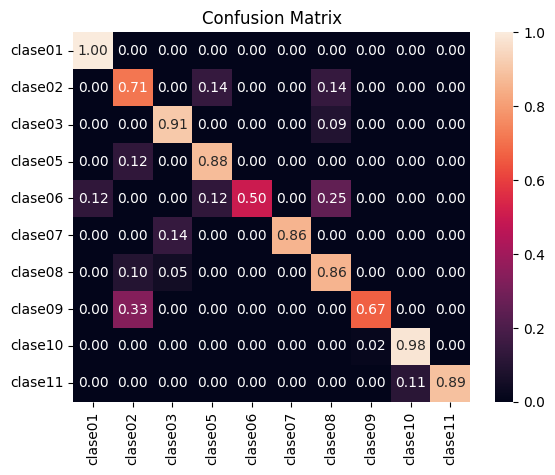

In [8]:
# 8. Evaluación final
_, test_acc, final_preds, final_labels = validate(model, test_loader)
print(f"Test Acc: {test_acc:.4f}")

all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [9]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final.pth")